# How networks learn

Notebook 5 ended with a problem: a hidden layer can solve XOR, but the perceptron rule cannot
find the hidden weights. This notebook solves it with **gradient descent** and
**backpropagation**, the algorithm behind practically every trained neural network. Then it asks
the question that matters more than training accuracy: does the network **generalise** to data
it has not seen?

The three families of learning:

| type | signal | example rule | notebook |
|---|---|---|---|
| supervised | a teacher gives the correct output | delta rule, backpropagation | here |
| unsupervised | input statistics only | Hebbian, competitive learning | 5, here |
| reinforcement | delayed, scalar reward | temporal-difference learning | 8 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.datasets import make_moons
from sklearn.model_selection import KFold

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(0)
_ = torch.manual_seed(0)

## Gradient descent on a loss surface

Learning means choosing parameters that make a loss small. For a linear unit $\hat y = w x + b$
and mean squared error

$$L(w, b) = \frac1n \sum_i (\hat y_i - y_i)^2,$$

the gradient points uphill, so we step the other way: $\theta \leftarrow \theta -
\eta\,\nabla_\theta L$. The learning rate $\eta$ controls the step size.

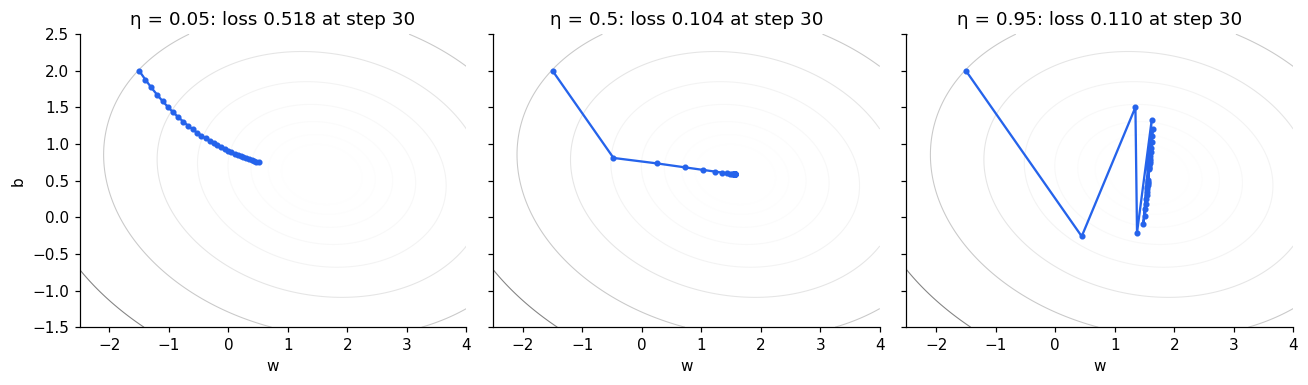

In [2]:
x = rng.uniform(-1, 1, 40)
y = 1.5 * x + 0.5 + rng.normal(0, 0.3, 40)

def loss(w, b):
    return np.mean((w * x + b - y) ** 2)

def grad(w, b):
    e = w * x + b - y
    return 2 * np.mean(e * x), 2 * np.mean(e)

def descend(eta, steps=30, start=(-1.5, 2.0)):
    w, b = start
    path = [(w, b)]
    for _ in range(steps):
        gw, gb = grad(w, b)
        w, b = w - eta * gw, b - eta * gb
        path.append((w, b))
    return np.array(path)

W, B = np.meshgrid(np.linspace(-2.5, 4, 200), np.linspace(-1.5, 2.5, 200))
Lgrid = np.mean((W[..., None] * x + B[..., None] - y) ** 2, axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, eta in zip(axes, [0.05, 0.5, 0.95]):
    path = descend(eta)
    ax.contour(W, B, Lgrid, levels=Lgrid.min() + np.geomspace(0.01, 15, 14), cmap="Greys", linewidths=0.7)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, color="#2563eb")
    ax.set(title=f"η = {eta}: loss {loss(*path[-1]):.3f} at step 30",
           xlabel="w", xlim=(-2.5, 4), ylim=(-1.5, 2.5))
    ax.grid(False)
axes[0].set_ylabel("b")
plt.tight_layout()
plt.show()

Too small a step crawls; a good step converges in a few iterations; too large a step overshoots
and zig-zags across the valley. Here any $\eta$ above 1 makes the zig-zag grow instead of
shrink, and the loss diverges. The limit is set by the curvature of the steepest direction. The surface here is a
bowl because the model is linear; for neural networks it is not, but the update is the same.

## The delta rule

Applying the update after every single example, rather than to the average loss, gives the
**delta rule** (Widrow-Hoff, or least mean squares):

$$\Delta w_j = \eta\,(t - \hat y)\,x_j .$$

It looks like the perceptron rule but uses the continuous error $t - \hat y$. It is also the
Rescorla-Wagner model of classical conditioning, where $t - \hat y$ is the prediction error
that drives learning. Notebook 8 extends that error to predictions about the future.

## Backpropagation

Take a network with one hidden layer of sigmoid units and a sigmoid output, trained with binary
cross-entropy (notebook 4):

$$\mathbf h = \sigma(W_1\mathbf x + \mathbf b_1), \qquad \hat y = \sigma(\mathbf w_2^\top \mathbf h + b_2).$$

The chain rule gives every gradient by passing an error signal backwards. For sigmoid output
with cross-entropy, the output error is simply $\delta_2 = \hat y - t$. Each hidden unit then
receives its share of that error, weighted by its outgoing weight and scaled by its own slope:

$$\delta_1 = (\mathbf w_2\,\delta_2) \odot \mathbf h \odot (1 - \mathbf h).$$

The weight gradients are outer products of each layer's error with its input, exactly as in
the delta rule: $\nabla W_1 = \delta_1 \mathbf x^\top$ and $\nabla \mathbf w_2 = \delta_2\,\mathbf h$.

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class MLP:
    def __init__(self, n_in, n_hidden, rng=rng):
        self.W1 = rng.normal(0, 1, (n_hidden, n_in))
        self.b1 = np.zeros(n_hidden)
        self.w2 = rng.normal(0, 1, n_hidden)
        self.b2 = 0.0

    def forward(self, X):
        self.X = X
        self.H = sigmoid(X @ self.W1.T + self.b1)
        self.yhat = sigmoid(self.H @ self.w2 + self.b2)
        return self.yhat

    def loss(self, t):
        p = np.clip(self.yhat, 1e-9, 1 - 1e-9)
        return -np.mean(t * np.log(p) + (1 - t) * np.log(1 - p))

    def backward(self, t):
        n = len(t)
        d2 = (self.yhat - t) / n                          # output error
        d1 = np.outer(d2, self.w2) * self.H * (1 - self.H)  # hidden errors
        return {"w2": self.H.T @ d2, "b2": d2.sum(),
                "W1": d1.T @ self.X, "b1": d1.sum(0)}

    def step(self, grads, eta):
        for k, g in grads.items():
            setattr(self, k, getattr(self, k) - eta * g)

Xx = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
tx = np.array([0, 1, 1, 0], float)
net = MLP(2, 3)
losses = []
for epoch in range(5000):
    net.forward(Xx)
    losses.append(net.loss(tx))
    net.step(net.backward(tx), eta=1.0)
print("XOR outputs after training:", net.forward(Xx).round(3))

XOR outputs after training: [0.002 0.998 0.998 0.002]


The network has learned XOR, including hidden weights that the perceptron rule could not find.

## Checking the gradients

A hand-derived gradient is easy to get subtly wrong. Two checks are standard: compare with a
finite-difference estimate, and compare with automatic differentiation. PyTorch's autograd
records the forward computation and applies the chain rule for us.

In [4]:
net = MLP(2, 3)
net.forward(Xx)
analytic = net.backward(tx)

eps = 1e-6
numeric = np.zeros_like(net.W1)
for idx in np.ndindex(net.W1.shape):
    old = net.W1[idx]
    net.W1[idx] = old + eps; net.forward(Xx); lp = net.loss(tx)
    net.W1[idx] = old - eps; net.forward(Xx); lm = net.loss(tx)
    net.W1[idx] = old
    numeric[idx] = (lp - lm) / (2 * eps)

W1 = torch.tensor(net.W1, requires_grad=True)
b1 = torch.tensor(net.b1, requires_grad=True)
w2 = torch.tensor(net.w2, requires_grad=True)
b2 = torch.tensor(net.b2, requires_grad=True)
H = torch.sigmoid(torch.tensor(Xx) @ W1.T + b1)
yhat = torch.sigmoid(H @ w2 + b2)
torch.nn.functional.binary_cross_entropy(yhat, torch.tensor(tx)).backward()

print("max |analytic − finite difference|:", np.abs(analytic["W1"] - numeric).max())
print("max |analytic − autograd|:         ", np.abs(analytic["W1"] - W1.grad.numpy()).max())

max |analytic − finite difference|: 4.306338792503528e-11
max |analytic − autograd|:          1.0408340855860843e-17


All three agree to numerical precision. From here on we let autograd compute gradients.

## Overfitting

A network with enough hidden units can fit almost any training set, including its noise. The
real test is held-out data. The *two moons* dataset is a simple nonlinear problem; we give the
network only 60 noisy training points.

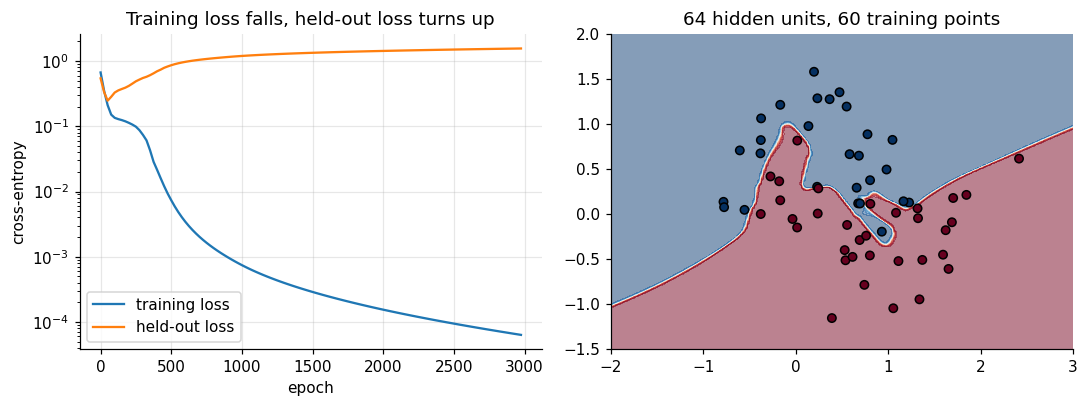

train acc = 1.00, held-out acc = 0.86


In [5]:
Xm, tm = make_moons(n_samples=1060, noise=0.3, random_state=1)
X_train, t_train, X_test, t_test = Xm[:60], tm[:60], Xm[60:], tm[60:]

def make_net(hidden):
    return torch.nn.Sequential(torch.nn.Linear(2, hidden), torch.nn.Tanh(),
                               torch.nn.Linear(hidden, hidden), torch.nn.Tanh(),
                               torch.nn.Linear(hidden, 1))

def train(model, X, t, epochs=3000, lr=0.01, weight_decay=0.0, X_val=None, t_val=None):
    X, t = torch.tensor(X, dtype=torch.float32), torch.tensor(t, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []
    for epoch in range(epochs):
        opt.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(model(X).squeeze(1), t)
        loss.backward()
        opt.step()
        if X_val is not None and epoch % 25 == 0:
            history.append((loss.item(), evaluate(model, X_val, t_val)[0]))
    return history

@torch.no_grad()
def evaluate(model, X, t):
    X, t = torch.tensor(X, dtype=torch.float32), torch.tensor(t, dtype=torch.float32)
    logits = model(X).squeeze(1)
    loss = torch.nn.functional.binary_cross_entropy_with_logits(logits, t).item()
    acc = ((logits > 0).float() == t).float().mean().item()
    return loss, acc

torch.manual_seed(0)
big = make_net(64)
hist = np.array(train(big, X_train, t_train, X_val=X_test, t_val=t_test))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ep = np.arange(len(hist)) * 25
axes[0].plot(ep, hist[:, 0], label="training loss")
axes[0].plot(ep, hist[:, 1], label="held-out loss")
axes[0].set(xlabel="epoch", ylabel="cross-entropy", yscale="log",
            title="Training loss falls, held-out loss turns up")
axes[0].legend()

gx, gy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
with torch.no_grad():
    zz = big(torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32)).reshape(gx.shape)
axes[1].contourf(gx, gy, torch.sigmoid(zz).numpy(), levels=20, cmap="RdBu_r", alpha=0.5)
axes[1].scatter(*X_train.T, c=t_train, cmap="RdBu_r", edgecolor="k", s=30)
axes[1].set(title="64 hidden units, 60 training points")
axes[1].grid(False)
plt.tight_layout()
plt.show()
print(f"train acc = {evaluate(big, X_train, t_train)[1]:.2f}, "
      f"held-out acc = {evaluate(big, X_test, t_test)[1]:.2f}")

The boundary wraps around individual training points. Training loss keeps falling towards zero
while held-out loss reaches a minimum and then rises: the network is memorising noise.

Three standard remedies are early stopping (halt near the held-out minimum), a smaller network,
and **weight decay**, which adds $\lambda\lVert\mathbf w\rVert^2$ to the loss and so prefers
smooth functions.

## Choosing complexity by cross-validation

The held-out set must not be used to choose the model, or its error stops being an honest
estimate. **k-fold cross-validation** chooses using the training data only: split it into $k$
folds, train on $k-1$, validate on the remaining one, rotate, and average.

In [6]:
def cv_loss(hidden, weight_decay, k=5, epochs=1500):
    losses = []
    for tr, va in KFold(k, shuffle=True, random_state=0).split(X_train):
        torch.manual_seed(0)
        m = make_net(hidden)
        train(m, X_train[tr], t_train[tr], epochs=epochs, weight_decay=weight_decay)
        losses.append(evaluate(m, X_train[va], t_train[va])[0])
    return np.mean(losses)

settings = [(h, wd) for h in (2, 8, 64) for wd in (0.0, 1e-2)]
scores = {s: cv_loss(*s) for s in settings}
for (h, wd), s in scores.items():
    print(f"hidden = {h:2d}, weight decay = {wd:<5}: CV loss = {s:.3f}")
best = min(scores, key=scores.get)
print("chosen:", best)

torch.manual_seed(0)
final = make_net(best[0])
train(final, X_train, t_train, epochs=1500, weight_decay=best[1])
print(f"held-out accuracy of chosen model: {evaluate(final, X_test, t_test)[1]:.2f} "
      f"(64 units, no decay, 3000 epochs: {evaluate(big, X_test, t_test)[1]:.2f})")

hidden =  2, weight decay = 0.0  : CV loss = 0.354
hidden =  2, weight decay = 0.01 : CV loss = 0.384
hidden =  8, weight decay = 0.0  : CV loss = 1.018
hidden =  8, weight decay = 0.01 : CV loss = 0.280
hidden = 64, weight decay = 0.0  : CV loss = 1.272
hidden = 64, weight decay = 0.01 : CV loss = 0.272
chosen: (64, 0.01)


held-out accuracy of chosen model: 0.91 (64 units, no decay, 3000 epochs: 0.86)


Cross-validation picks the setting from training data alone, and only then is the held-out set
consulted, once. Notice what it chose: not the smallest network but the largest one *with*
weight decay. Without decay, larger networks do worse; with it, extra capacity is harmless. How
a network is constrained matters more than how big it is.

## Unsupervised contrast: competitive learning

Without a teacher, a network can still discover structure. In **competitive learning**, output
units compete for each input; only the winner, the unit whose weight vector is closest, moves
its weights towards the input:

$$\mathbf w_{\text{win}} \leftarrow \mathbf w_{\text{win}} + \eta\,(\mathbf x - \mathbf w_{\text{win}}).$$

Each unit ends up at the centre of a cluster. This is online k-means, and a simple model of how
feature detectors could self-organise.

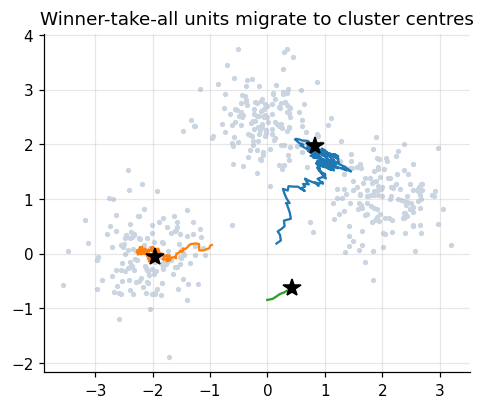

In [7]:
centers = np.array([[-2, 0], [2, 1], [0, 2.5]])
Xu = np.vstack([rng.normal(c, 0.5, (150, 2)) for c in centers])
rng.shuffle(Xu)
Wc = rng.normal(0, 0.5, (3, 2))
trace = [Wc.copy()]
for x_ in Xu:
    win = np.argmin(((Wc - x_) ** 2).sum(1))
    Wc[win] += 0.05 * (x_ - Wc[win])
    trace.append(Wc.copy())
trace = np.array(trace)

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(*Xu.T, s=6, color="#cbd5e1")
for j in range(3):
    ax.plot(trace[:, j, 0], trace[:, j, 1], lw=1.5)
    ax.plot(*trace[-1, j], "k*", ms=12)
ax.set(title="Winner-take-all units migrate to cluster centres")
plt.show()

## Summary

- Gradient descent steps against the gradient of a loss; the learning rate trades speed for
  stability.
- The delta rule is gradient descent for a linear unit, and the Rescorla-Wagner rule in
  disguise.
- Backpropagation passes errors backwards with the chain rule; check hand-written gradients
  against finite differences or autograd.
- Training error says little about generalisation. Use held-out data, and choose complexity
  by cross-validation on the training set.
- Competitive learning finds clusters without a teacher.